In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

In [ ]:
# Load data
df = yf.download('USDJPY=X', start="2000-01-01", end="2020-01-01")
df.head()

/tmp/ipykernel_27264/1964874072.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download('USDJPY=X', start="2000-01-01", end="2020-01-01")
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,USDJPY=X,USDJPY=X,USDJPY=X,USDJPY=X,USDJPY=X
Date,,,,,
2000-01-03,101.690002,103.330002,101.309998,102.070000,0
2000-01-04,103.139999,103.320000,101.470001,101.639999,0
2000-01-05,104.089996,104.480003,102.750000,103.129997,0
2000-01-06,105.230003,105.559998,103.900002,104.089996,0
2000-01-07,105.330002,105.879997,104.830002,105.260002,0


In [ ]:
if isinstance(df.columns, pd.MultiIndex):
  df.columns = df.columns.get_level_values(0)

In [ ]:
price = df['Close']
df['Returns'] = price.pct_change()

In [ ]:
ma = price.rolling(20).mean()
std = price.rolling(20).std()
lower = ma - 2 * std
upper = ma + 2 * std

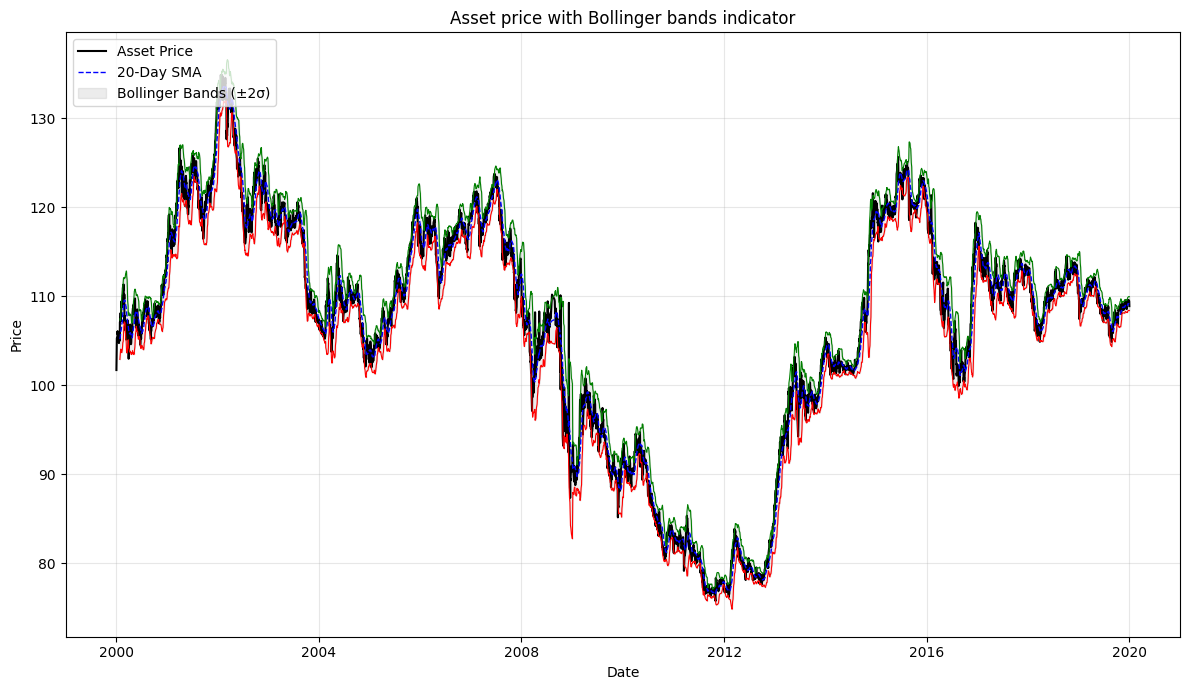

In [ ]:
# Visualize Bollinger Bands
plt.figure(figsize=(12, 7))

# Plot Price, SMA, and Bands
plt.plot(df.index, df['Close'], color='black', linewidth=1.5, label='Asset Price')
plt.plot(df.index, ma, color='blue', linestyle='--', linewidth=1, label='20-Day SMA')
plt.plot(df.index, upper, color='green', linewidth=0.8)
plt.plot(df.index, lower, color='red', linewidth=0.8)

# Shaded Area Between Bands
plt.fill_between(df.index, lower, upper, color='gray', alpha=0.15, label='Bollinger Bands (±2σ)')

# Formatting
plt.title("Asset price with Bollinger bands indicator")
plt.ylabel("Price")
plt.xlabel("Date")
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')

plt.tight_layout()

In [ ]:
position = 0  # 1 = long, -1 = short, 0 = flat

positions = []
entries = []
exits = []

for i in range(len(df)):
    price = df['Close'].iloc[i]
    ma_ = ma.iloc[i]
    lower_ = lower.iloc[i]
    upper_ = upper.iloc[i]

    entry = 0
    exit_ = 0

    # -----------------------
    # ENTRY RULES
    # -----------------------
    if position == 0:
        if price < lower_:
            position = 1
            entry = 1
        elif price > upper_:
            position = -1
            entry = -1

    # -----------------------
    # EXIT RULES (MA REVERSION)
    # -----------------------
    elif position == 1:
        if price >= ma_:
            position = 0
            exit_ = 1

    elif position == -1:
        if price <= ma_:
            position = 0
            exit_ = -1

    # store results
    positions.append(position)
    entries.append(entry)
    exits.append(exit_)

# attach to dataframe
df['position'] = positions
df['entry'] = entries
df['exit'] = exits

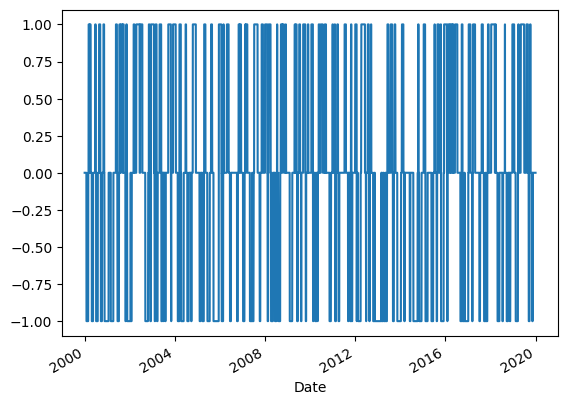

In [ ]:
df['position'].plot();

In [ ]:
algo_returns = df['position'].shift(1) * df['Returns']

In [ ]:
# Compute cumulative return
cumulative_return = (1 + algo_returns).cumprod()
benchmark = (1 + df['Returns']).cumprod()

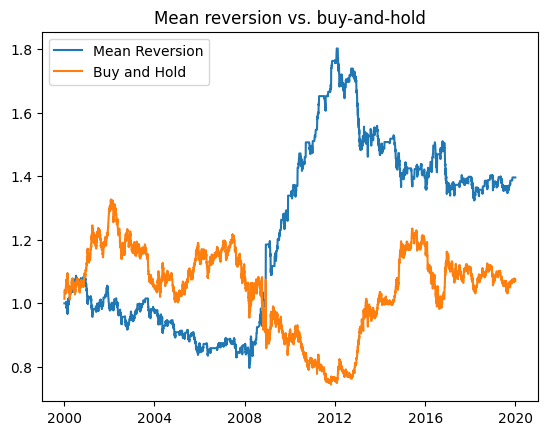

In [ ]:
# Plot cumulative return vs. buy-and-hold
plt.title("Mean reversion vs. buy-and-hold")
plt.plot(cumulative_return, label='Mean Reversion')
plt.plot(benchmark, label='Buy and Hold')
plt.legend(loc='upper left');